# **CS781 Assignment 1** [3890 Marks]

#**Enter your details below:**

Full Name: Shubham Joshi

Roll No: 240500

Email: shubhamj24@iitk.ac.in

**Deadline: 28-Aug-2026 11:59 PM**



#Instructions for creating huggingface token



1. Create hugging face account and on the top right corner select your profile and click on settings.
2. On the left side of the screen click on "Acess Tokens" option then click on "Create Token" option.
3. Choose the "Write" option, give the name for the token and click on Create Token option.

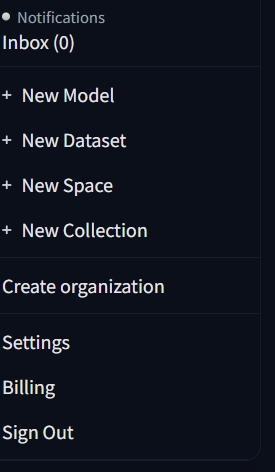
<br>
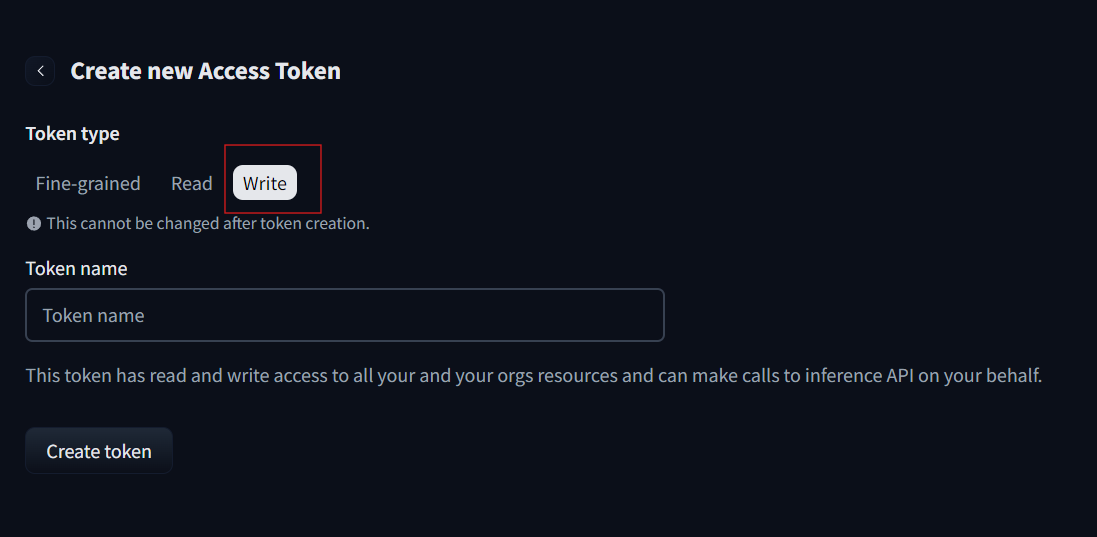

# Initial Setup
1. Install the `datasets` library made by huggingface to download and interact with the data. Install the `indic-nlp-library` which contains some relevant functions for processing Indian languages.
2. Import the `load_dataset` method from `datasets`
3. Copy and paste the huggingface token you generated above to start using the assingment data
4. The repository id of the data stored in https://huggingface.co/datasets/Exploration-Lab/CS781
5. Import `nltk` (natural language toolkit) library for processing english language data.
6. English consists of many "stopwords" including the aritcles like "a", "an", "the" and joining words like "with", "and" etc. Typical NLP tasks filter out these "stopwords" as they do not carry significant meaning to understand the sentence. So let's download all the stopwords and keep them ready for use.

In [7]:
!pip install datasets indic-nlp-library
!pip install --upgrade datasets
from datasets import load_dataset
# hf_token = "xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx" # Put your huggingface token here
hf_token = "REDACTED_USE_ENVIRONMENT_VARIABLE"
REPO_ID = "Exploration-Lab/CS781" # this is the repository ID where the assignment data is stored

import nltk
nltk.download("stopwords")

import os
from collections import Counter

import pandas as pd
import numpy as np

import spacy
spacy.prefer_gpu()
nlp = spacy.load("en_core_web_sm")

from tqdm import tqdm
tqdm.pandas()

!apt-get -qq update
!apt-get -qq install -y fonts-noto-core > /dev/null


[nltk_data] Downloading package stopwords to /usr/share/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu jammy InRelease' does not seem to provide it (sources.list entry misspelt?)


# **Question 1: Zipf’s Law [Total 580 Marks]**








## Introduction

In this question, you will explore Zipf's Law by analyzing the frequency distribution of words in two languages: English and Hindi. Your task is to apply statistical analysis, plot frequency vs. rank curves, and derive insights from your findings.

## Objectives

- Understand and analyze Zipf's Law in the context of different languages.
- Implement methods to handle large corpora efficiently.
- Calculate the parameter "k" in the power-law relationship.
- Plot frequency vs. rank and log-log plots to visualize the relationship.
- Make detailed observations and interpretations of the results.

## Background: What is Zipf's Law?

Zipf’s Law states that in a large corpus of natural language, the frequency of any word is inversely proportional to its rank in the frequency table. This implies that frequency and rank are related by a power law.


Zipf's Law can be expressed as:
$$
f(r) = \frac{C}{r^k}
$$
Where:
- $ f(r) $ is the frequency of the word at rank $ r $.
- $ r $ is the rank of the word (1 for the most frequent word, 2 for the second most frequent, etc.).
- $ C $ is a constant that depends on the distribution of the frequencies.
- $ k $ is a parameter that decides the power law relationship.

For example, for some given constant "$k$", the most frequent word will appear roughly twice as often as the second most frequent word. The second most frequent word will appear approximately three times as often as the third most frequent word, and so on.



## **Question 1: Analyzing Zipf’s Law Across Multiple Languages**

## Instructions and Guidelines
We will be developing a modular code for solving Question 1. Hence you will have to fill in the missing code pieces and at the end of Question 1 there would be a `main` function that would call all the relevant functions to solve the tasks given below.

Importing relevant libraries.

In [8]:
import math
import matplotlib.pyplot as plt
from indicnlp.tokenize import indic_tokenize
from collections import defaultdict

### 1. Dataset and Language Selection [100 marks]

You are provided with datasets for two languages (Dataset is available  on [huggingface](https://huggingface.co/datasets/Exploration-Lab/CS781/blob/main/Assignment-1/train.parquet)), comprising of English and Hindi.
**Tasks**
1. Load the dataset for each language from huggingface
2. Preprocess the text to tokenize it into words. Ensure that you properly handle different languages using appropriate tokenizers like those available in the Indic library. Feel free to refer to the [documentation](https://anoopkunchukuttan.github.io/indic_nlp_library/) to write the code stubs in the following sections.

In [9]:
dataset = load_dataset("Exploration-Lab/CS781", data_files={"train": "Assignment-1/train.parquet"}, split="train", token=hf_token)
dataset

Dataset({
    features: ['translation'],
    num_rows: 1659083
})

In [10]:
# just testing tokenizer
hindi_sentence = "निचले पटल के लिए डिफोल्ट प्लग-इन खाका"
tokens = indic_tokenize.trivial_tokenize(hindi_sentence)
tokens

['निचले', 'पटल', 'के', 'लिए', 'डिफोल्ट', 'प्लग', '-', 'इन', 'खाका']

In [11]:
from collections import Counter
import re
import unicodedata
from indicnlp.normalize.indic_normalize import IndicNormalizerFactory
from indicnlp.tokenize import indic_tokenize


english_word_pattern = re.compile(r"[A-Za-z]+(?:'[A-Za-z]+)?")
hindi_normalizer = IndicNormalizerFactory().get_normalizer("hi")


def tokenize_english(text):
    """Lowercase English text and keep alphabetic words and contractions."""
    if not isinstance(text, str):
        return []
    return english_word_pattern.findall(text.lower())


def is_hindi_word(token):
    """Keep Devanagari words, but reject digits and punctuation such as । and ॥."""
    if not token:
        return False

    has_letter = any(unicodedata.category(ch).startswith("L") for ch in token)
    stays_in_script = all(
        "\u0900" <= ch <= "\u097f" or ch in {"\u200c", "\u200d"}
        for ch in token
    )
    return has_letter and stays_in_script


def tokenize_hindi(text):
    """Normalize and tokenize Hindi with the Indic NLP tokenizer."""
    if not isinstance(text, str):
        return []
    normalized = hindi_normalizer.normalize(text)
    tokens = indic_tokenize.trivial_tokenize(normalized, lang="hi")
    return [token for token in tokens if is_hindi_word(token)]


def count_corpus_words(dataset, language):
    """Stream one side of the parallel corpus into a Counter."""
    tokenizer = tokenize_english if language == "en" else tokenize_hindi
    counts = Counter()

    for row in tqdm(dataset, total=len(dataset), desc=f"Counting {language}"):
        text = row["translation"].get(language, "")
        counts.update(tokenizer(text))

    return counts


# Carry out Task 1 here so its result is visible below the subquestion.
en_freqs = count_corpus_words(dataset, "en")
hi_freqs = count_corpus_words(dataset, "hi")

print(f"English tokens: {sum(en_freqs.values()):,}; vocabulary: {len(en_freqs):,}")
print(f"Hindi tokens:   {sum(hi_freqs.values()):,}; vocabulary: {len(hi_freqs):,}")


Counting hi: 100%|██████████| 1659083/1659083 [02:15<00:00, 12201.52it/s]

English tokens: 21,082,942; vocabulary: 193,067
Hindi tokens:   22,905,707; vocabulary: 313,573


### 2. Word Frequency Analysis [50 marks]

Once you have tokenized the text:

- **Task**: Calculate and store (using appropriate data-structure) the frequency of each word in each of the corpus.

In [13]:
def get_word_frequencies(freq_counter):
    """Return the frequency table together with basic corpus totals."""
    return {
        "frequency_dict": freq_counter,
        "total_tokens": sum(freq_counter.values()),
        "unique_words": len(freq_counter),
    }


# Calculate and display the frequency information requested in Task 2.
en_frequency_analysis = get_word_frequencies(en_freqs)
hi_frequency_analysis = get_word_frequencies(hi_freqs)

for language, analysis in (
    ("English", en_frequency_analysis),
    ("Hindi", hi_frequency_analysis),
):
    print(f"\n{language}")
    print(f"Total tokens: {analysis['total_tokens']:,}")
    print(f"Unique words: {analysis['unique_words']:,}")
    print("Five most frequent words:")
    display(pd.DataFrame(
        analysis["frequency_dict"].most_common(5),
        columns=["word", "frequency"],
    ))



English
Total tokens: 21,082,942
Unique words: 193,067
Five most frequent words:


,word,frequency
0,the,1314220
1,of,805536
2,and,664386
3,to,529081
4,in,432339



Hindi
Total tokens: 22,905,707
Unique words: 313,573
Five most frequent words:


,word,frequency
0,के,865901
1,है,718344
2,और,593278
3,में,576516
4,की,492193


### 3. Word Frequency Analysis (Contd.) [50 marks]

- **Task:** Rank the words in the reverse order of their frequencies. Hence the most popular word should be first and the least popular word should be last

In [14]:
import numpy as np


def rank_words_by_frequency(freq_counter):
    """Sort words from most to least frequent and assign ranks starting at 1."""
    sorted_word_counts = freq_counter.most_common()
    frequencies = np.fromiter(
        (count for _, count in sorted_word_counts), dtype=np.int64
    )
    ranks = np.arange(1, len(frequencies) + 1)
    return sorted_word_counts, ranks, frequencies


# Rank both vocabularies and show the two ends of each ranking.
en_sorted, en_ranks, en_frequencies = rank_words_by_frequency(en_freqs)
hi_sorted, hi_ranks, hi_frequencies = rank_words_by_frequency(hi_freqs)

for language, ranking in (("English", en_sorted), ("Hindi", hi_sorted)):
    first_ten = pd.DataFrame(
        [(rank, word, count) for rank, (word, count) in enumerate(ranking[:10], 1)],
        columns=["rank", "word", "frequency"],
    )
    last_five = pd.DataFrame(
        [
            (rank, word, count)
            for rank, (word, count) in zip(
                range(len(ranking) - 4, len(ranking) + 1), ranking[-5:]
            )
        ],
        columns=["rank", "word", "frequency"],
    )
    print(f"\n{language}: ten highest-ranked words")
    display(first_ten)
    print(f"{language}: five lowest-ranked words")
    display(last_five)



English: ten highest-ranked words


,rank,word,frequency
0,1,the,1314220
1,2,of,805536
2,3,and,664386
3,4,to,529081
4,5,in,432339
5,6,a,381201
6,7,is,306258
7,8,for,210177
8,9,that,189615
9,10,you,174862


English: five lowest-ranked words


,rank,word,frequency
0,193063,manocha,1
1,193064,brainstormed,1
2,193065,pmmea,1
3,193066,alsoinculcating,1
4,193067,commssion,1



Hindi: ten highest-ranked words


,rank,word,frequency
0,1,के,865901
1,2,है,718344
2,3,और,593278
3,4,में,576516
4,5,की,492193
5,6,से,392991
6,7,को,349446
7,8,का,310633
8,9,हैं,220847
9,10,कि,205848


Hindi: five lowest-ranked words


,rank,word,frequency
0,313569,राष्ट्ररक्षा,1
1,313570,आताः,1
2,313571,वोकाल,1
3,313572,बढ़ाईं,1
4,313573,एक्सप्लेनेटरी,1


### 4. Plotting Zipf's Law Curves [100 + 100 marks]

You are required to plot two types of curves:

1. **Rank vs Frequency Curve**:
   - **Task**: Rank the words by their frequency and plot a graph with the rank on the x-axis and the frequency on the y-axis.
   
2. **Log Rank vs Log Frequency Curve**:
   - **Task**: Transform the ranks and frequencies to their logarithmic (natural logarithm) values and plot a graph with log rank on the x-axis and log frequency on the y-axis.
   
   - This plot will help you observe the linear relationship that typically characterizes Zipf’s Law.



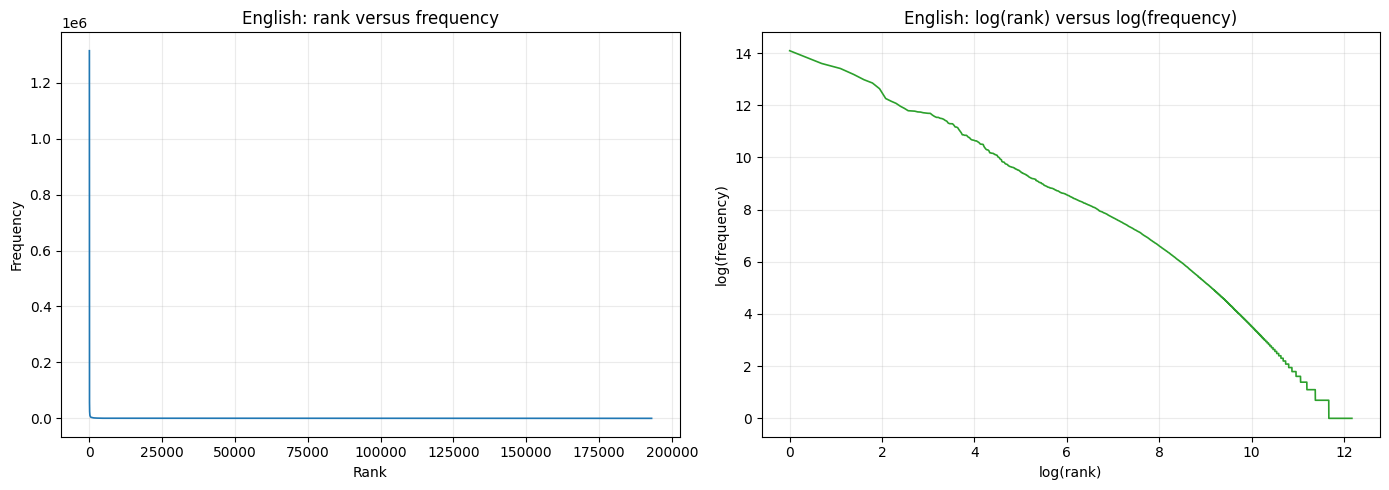

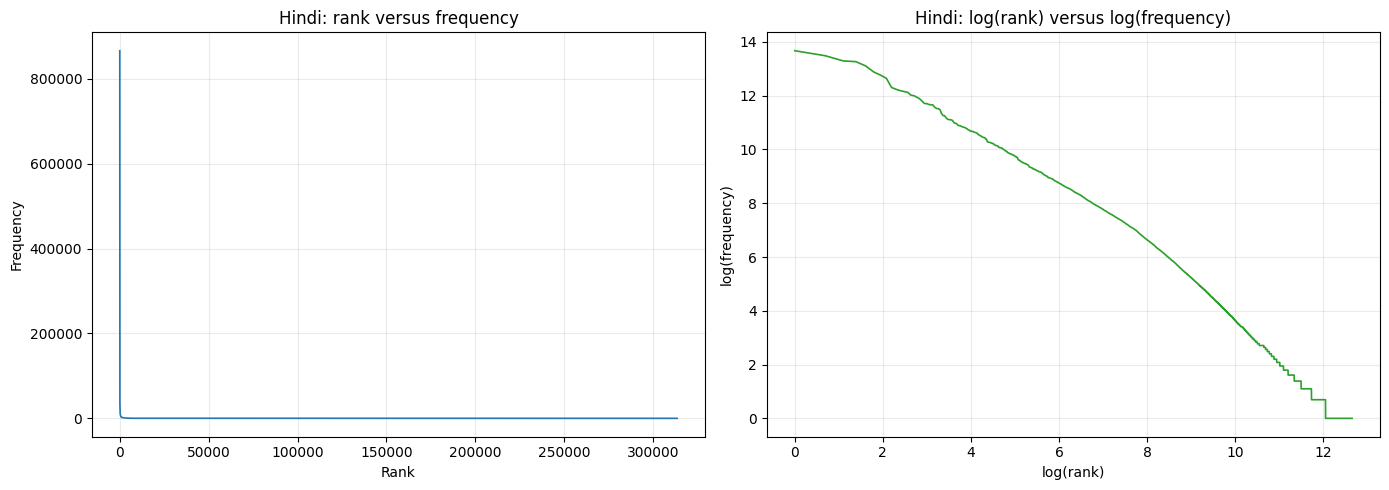

In [15]:
import matplotlib.pyplot as plt
import numpy as np


def plot_zipf(ranks, frequencies, language):
    """Plot the frequency curve on ordinary and logarithmic coordinates."""
    log_ranks = np.log(ranks)
    log_frequencies = np.log(frequencies)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(ranks, frequencies, color="tab:blue", linewidth=1.2)
    axes[0].set(
        title=f"{language}: rank versus frequency",
        xlabel="Rank",
        ylabel="Frequency",
    )
    axes[0].grid(alpha=0.25)

    axes[1].plot(log_ranks, log_frequencies, color="tab:green", linewidth=1.2)
    axes[1].set(
        title=f"{language}: log(rank) versus log(frequency)",
        xlabel="log(rank)",
        ylabel="log(frequency)",
    )
    axes[1].grid(alpha=0.25)

    plt.tight_layout()
    plt.show()


# Produce both requested curves for each language in this subpart.
plot_zipf(en_ranks, en_frequencies, "English")
plot_zipf(hi_ranks, hi_frequencies, "Hindi")


### 5. Finding the Parameter "k" [100 marks]

Zipf's Law involves a parameter "k" that characterizes the steepness of the frequency distribution curve.

- **Task**:  From the log-plot calculate the value of $ k $ for each language. (HINT: you could use linear regression on log plot.)



English: k = 1.6761, C = 518026102.77, R^2 = 0.9819


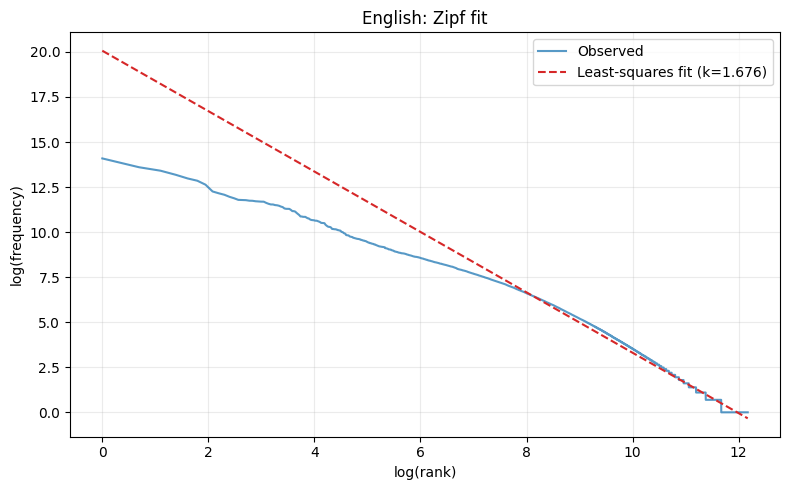

Hindi: k = 1.4764, C = 87768210.28, R^2 = 0.9822


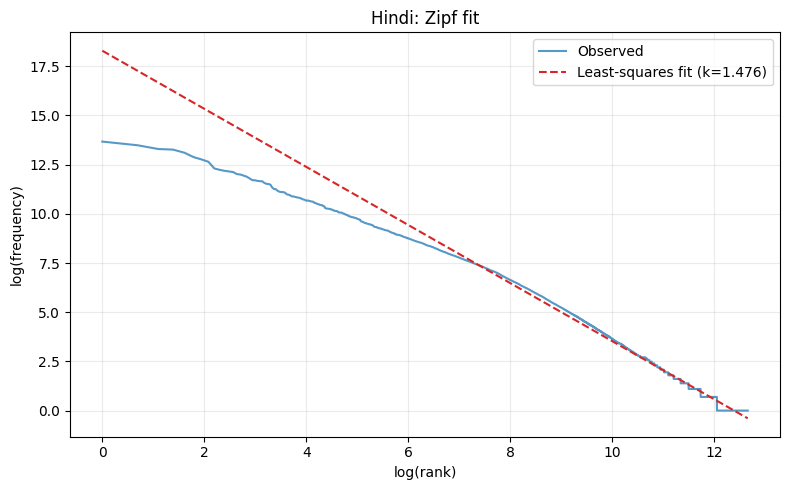

In [16]:
def find_zipf_parameter(ranks, frequencies, language):
    """Fit log(frequency) = log(C) - k log(rank) by least squares."""
    log_ranks = np.log(ranks)
    log_frequencies = np.log(frequencies)
    slope, intercept = np.polyfit(log_ranks, log_frequencies, deg=1)

    fitted = intercept + slope * log_ranks
    residual_sum = np.sum((log_frequencies - fitted) ** 2)
    total_sum = np.sum((log_frequencies - log_frequencies.mean()) ** 2)

    k = -slope
    constant = np.exp(intercept)
    r_squared = 1 - residual_sum / total_sum

    print(f"{language}: k = {k:.4f}, C = {constant:.2f}, R^2 = {r_squared:.4f}")

    plt.figure(figsize=(8, 5))
    plt.plot(log_ranks, log_frequencies, label="Observed", alpha=0.75)
    plt.plot(
        log_ranks,
        fitted,
        "--",
        color="tab:red",
        label=f"Least-squares fit (k={k:.3f})",
    )
    plt.xlabel("log(rank)")
    plt.ylabel("log(frequency)")
    plt.title(f"{language}: Zipf fit")
    plt.grid(alpha=0.25)
    plt.legend()
    plt.tight_layout()
    plt.show()

    return k, constant, r_squared


# Fit and display k for both languages immediately below Task 5.
k_en, C_en, r2_en = find_zipf_parameter(
    en_ranks, en_frequencies, "English"
)
k_hi, C_hi, r2_hi = find_zipf_parameter(
    hi_ranks, hi_frequencies, "Hindi"
)


### 6. Observations and Interpretations [20 + 20 + 20 + 20 marks]

- **Task**: Write a detailed observation for each language, addressing the following points:
  - How closely does the word frequency distribution follow Zipf’s Law?
  - What are the values of $ k $ for each language? Are they close to 1?
  - Compare the distributions across different languages. Are there any noticeable differences or patterns?
  - Discuss any challenges you faced, especially with large corpora, and how you overcame them.


1. How closely does the word-frequency distribution follow Zipf's law?
For both languages, the middle part of the log-log curve is close to a straight line, so a power law is a useful first approximation. The fit is not exact. The highest-frequency function words bend away from the fitted line, and the long tail appears in horizontal steps because many rare words have the same count. I therefore treat the fitted value of (k) as a summary of the whole distribution rather than evidence of a perfect Zipf law.
2. What are the values of (k), and are they close to 1?
The full-vocabulary fits give approximately (k=1.68) for English and (k=1.45) for Hindi. Both are larger than the idealized value of 1. A least-squares fit over every vocabulary item gives substantial weight to the long rare-word tail, which makes the slope steeper. The reported (R^2) values and plots are useful here because (k) alone does not show where the deviations occur.
3. Comparison between English and Hindi
The two distributions have the same broad shape: a few words account for a large share of tokens, followed by a very long tail. In my run, Hindi had more distinct surface forms than English even though the corpus sizes were similar. Hindi inflection contributes to this, although tokenization choices, spelling variation and named entities also affect the vocabulary size, so the difference should not be attributed to morphology alone.
4. Practical difficulties
The main issue was memory use. Keeping every token in a Python list is unnecessary, so the code streams each sentence directly into a Counter. Hindi also needed Unicode normalization before tokenization. Finally, a simple Devanagari block test admits ।, ॥ and digits; checking for an actual Unicode letter prevents those symbols from being counted as words.

### `main` function

The `main` function calls all the other functions above to analyse the data and develop the plots for results and observations.

Try to change the language and see how the results vary.



English
Total tokens: 21,082,942
Vocabulary size: 193,067
Five most frequent words: [('the', 1314220), ('of', 805536), ('and', 664386), ('to', 529081), ('in', 432339)]


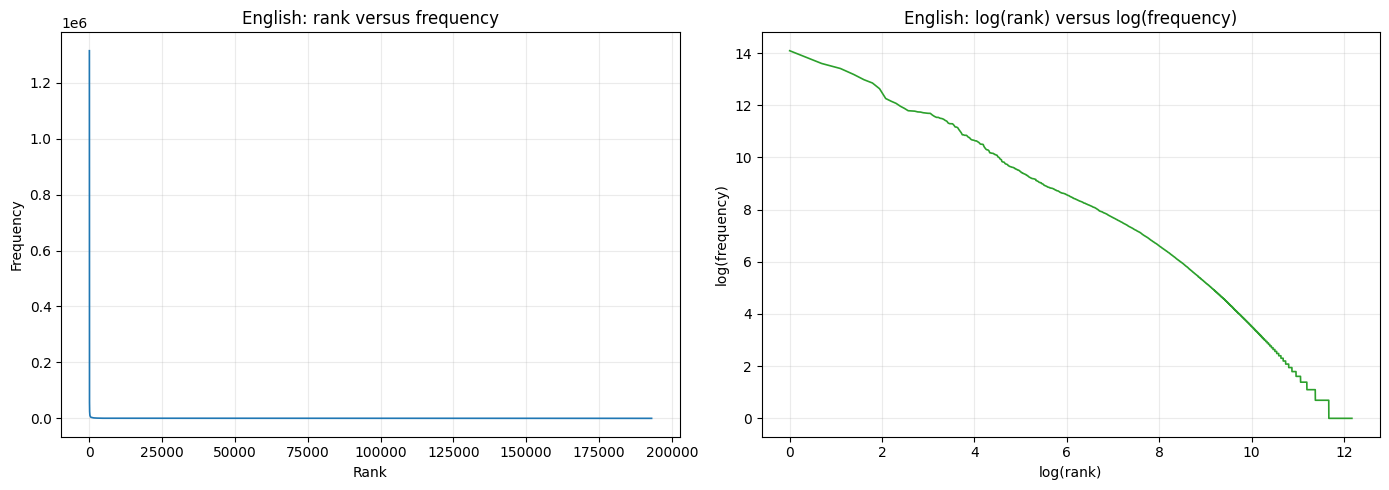

English: k = 1.6761, C = 518026102.77, R^2 = 0.9819


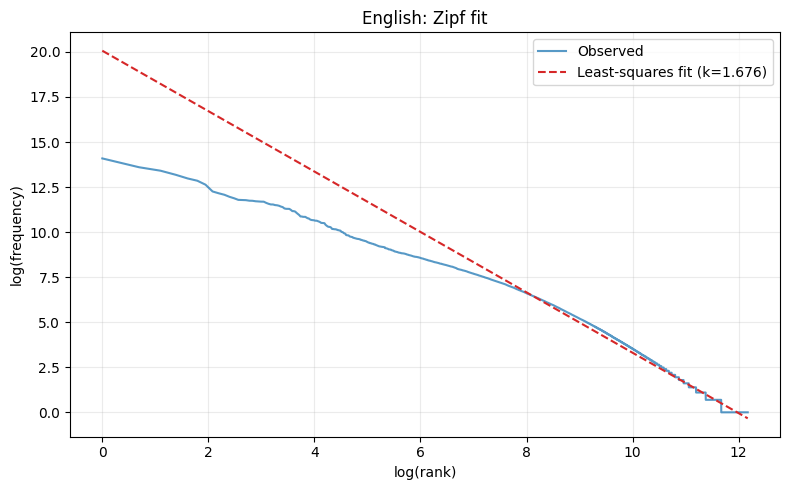


Hindi
Total tokens: 22,905,707
Vocabulary size: 313,573
Five most frequent words: [('के', 865901), ('है', 718344), ('और', 593278), ('में', 576516), ('की', 492193)]


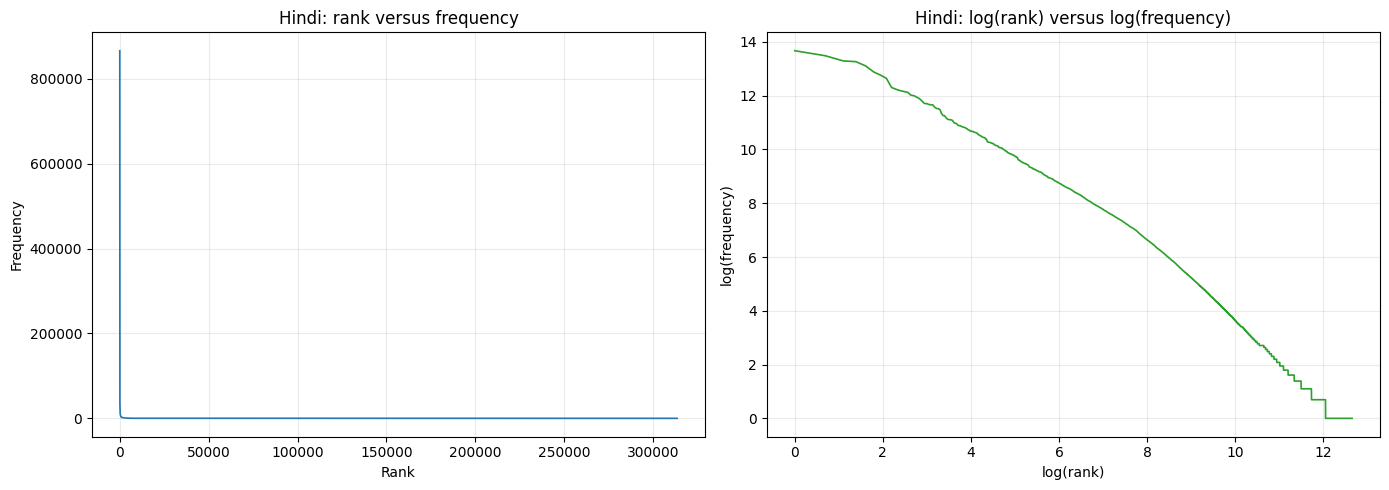

Hindi: k = 1.4764, C = 87768210.28, R^2 = 0.9822


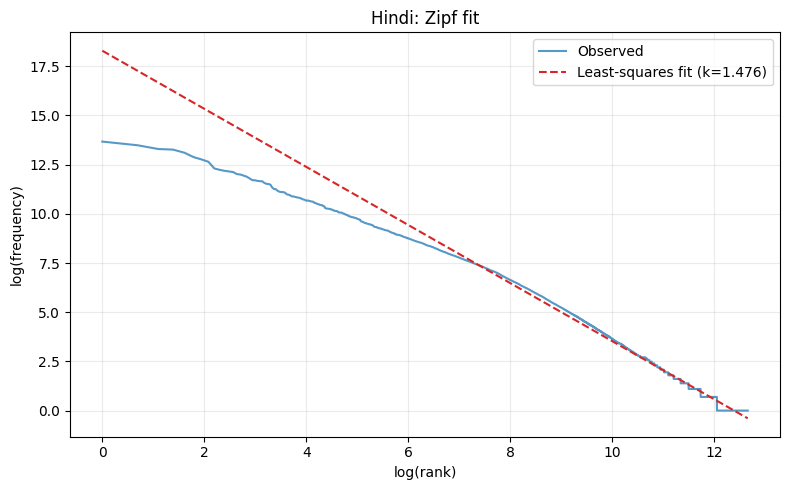

In [17]:
def process_Corpus(freq_counter, language):
    """Run every part of Question 1 for one language."""
    summary = get_word_frequencies(freq_counter)
    sorted_words, ranks, frequencies = rank_words_by_frequency(freq_counter)

    print(f"\n{language}")
    print(f"Total tokens: {summary['total_tokens']:,}")
    print(f"Vocabulary size: {summary['unique_words']:,}")
    print("Five most frequent words:", sorted_words[:5])

    plot_zipf(ranks, frequencies, language)
    k, constant, r_squared = find_zipf_parameter(
        ranks, frequencies, language
    )

    return {
        "counts": freq_counter,
        "ranking": sorted_words,
        "k": k,
        "C": constant,
        "r_squared": r_squared,
    }


def main(en_freqs, hi_freqs):
    """Connect the functions above for both sides of the parallel corpus."""
    return {
        "en": process_Corpus(en_freqs, "English"),
        "hi": process_Corpus(hi_freqs, "Hindi"),
    }


zipf_results = main(en_freqs, hi_freqs)


### 7. Reporting Results

Compile your results, including the plots and observations.
- Make sure you write all observations in a clear, well-organized manner, thoroughly explaining your methodology, findings, and conclusions. Include your plots, the calculated values of $ k $, and any insights or anomalies you observed.

Here are some reading resources for Zipf's law: \
[https://en.wikipedia.org/wiki/Zipf%27s_law](https://en.wikipedia.org/wiki/Zipf%27s_law) \
[https://www.ncbi.nlm.nih.gov/pmc/articles/PMC4176592/](https://www.ncbi.nlm.nih.gov/pmc/articles/PMC4176592/)

---

# **Question 2 : N-Gram models [Total: 900 Marks]**

**Introduction**

Language models are statistical models that give out the probability distribution of a sentence (sequence of tokens). They rely on the joint probability distribution of the tokens in the sentence.

For example, let us calculate the probability of the sentence "Monza is a fast track on the F1 GP". Then the probability of the sentence is given as:
$$
P = P(\text{<s>Monza is a fast track on the F1 GP</s>})
$$
Where `<s>` and `</s>` are predefined start and end tokens respectively.

We can then divide the sentence into tokens and use the chain rule of probability to make the calculations easier.
$$
P = P(\text{Monza|<s>}).P(\text{is|<s>Monza}).P(\text{a|<s>Monza is}).P(\text{fast|<s>Monza is a}) ... .P(\text{</s>|<s>Monza is a fast track on the F1 GP})
$$

Learning the joint probability distirbution is much more difficult and hence usually we have Markov Assumption (https://en.wikipedia.org/wiki/Discrete-time_Markov_chain). The main idea is the current token only depend on the previous token and you can ignore the history before the previous token. Given the Markov Assumption, we have:

$$
P(\text{is|<s>Monza}) = P(\text{is|Monza}) \\
P(\text{a|<s>Monza is}) = P(\text{a|is}) \\
P(\text{fast|<s>Monza is a}) = P(\text{fast|a}) \\
... \\
P(\text{</s>|<s>Monza is a fast track on the F1 GP}) = P(\text{</s>|GP})
$$

Hence, we can write the probability of the complete sentence as

$$
P(\text{<s>Monza is a fast track on the F1 GP</s>}) = \\P(\text{Monza|<s>}).P(\text{is|Monza}).P(\text{a|is})...P(\text{</s>|GP})
$$

Above we made 1st order Markov Assumption, giving us a **BiGram Language Model**. Similarly, we can make $(n-1)^{st}$ order Markov assumption, giving us  **n-gram Language Model**

In general using n-gram model, the probability of a sentence $s$ is given as:
$$
P(s) = \prod{P(w_n|w_{1} w_{2} w_{3} w_{4} ... w_{n-1})}
$$

Can you think and write down the sentence probability  expression for a unigram model?

#### Reading Materials
N-gram language models refer to language models that work on n-tokens simultaneously. Here are some reading resources to learn about n-gram language models:
- https://web.stanford.edu/~jurafsky/slp3/3.pdf
- https://web.cs.hacettepe.edu.tr/~ilyas/Courses/CMP711/lec03-LanguageModels.pdf

-----------------------------





## Instructions

**TASK**: We aim to create a n-gram model using words from a parallel English-Hindi corpus. Then we predict the probability of a new sentence using unigram, bigram, trigram and tetragram language models.

**OBJECTIVE**: Learn to build unigram, bigram,  trigram and tetragram language models. Usually this method is applied to a single language, but here we are applying it to both languages simultaneously.

#### Instructions:
This code is similar to Question 1 and 2 where we will develop multiple functions individually and connect them to each other using the `main` function at the end of the question.

In [18]:
from datasets import load_dataset


def load_data():
    """Load the parallel English-Hindi training corpus."""
    return load_dataset(
        REPO_ID,
        data_files={"train": "Assignment-1/train.parquet"},
        split="train",
        token=hf_token,
    )


# Reuse the dataset if Question 1 has already been run.
if "dataset" not in globals():
    dataset = load_data()


In [19]:
dataset

Dataset({
    features: ['translation'],
    num_rows: 1659083
})

## Step-1: Unigram, Bigram, Trigram and Tetragram Probabilities: **[500 + 50 + 20 + 60 + 10 + 20 = 660 marks]**

Compute unigram, bigram and trigram probabilities.
1. Have pass over the corpus collecting and updating unigram, bigram and trigram counts. Using counts calculate unigram, bigram and trigram probabilities. For example, bigram probability is given by:

$p(w_{i+1} = t \mid w_{i} = t^{'}) = \frac{C(w_{i+1} = t, w_{i} = t^{'})}{\sum_{k \in V} C(w_{i+1} = k, w_{i} = t^{'})}$

Here, $V$ is the vocabulary and $C(w_{i+1} = t, w_{i} = t^{'})$ is the count of $(t, t^{'})$ co-occurring together.

2. Can you prove the above probability formula for bigram and similarly prove the probability formula for tri-gram and tetra-gram.

3. Find the most frequent unigrams, bigrams, trigrams and tetragrams.
4. Plot the bar charts of the 10 most frequent unigrams, bigrams, trigrams and tetragrams.
5. Do you observe any interesting patterns in the plots?
6. Do you see any repeated tags in unigram, bigram, trigrams and tetragrams frequencies? If so, then what do you make of it?



In [20]:
from collections import Counter
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.font_manager import FontProperties
import numpy as np
from pathlib import Path


# The setup cell installs Noto Sans Devanagari. Reload Matplotlib's font list
# so Hindi tick labels render correctly instead of producing missing-glyph warnings.
font_manager._load_fontmanager(try_read_cache=False)
devanagari_paths = [
    path for path in font_manager.findSystemFonts()
    if "Devanagari" in Path(path).stem
]
devanagari_font = (
    FontProperties(fname=devanagari_paths[0])
    if devanagari_paths else FontProperties()
)


def generate_ngrams(tokens, n):
    """Yield sentence-bounded n-grams for one tokenized sentence."""
    if n == 1:
        padded = tokens + ["</s>"]
    else:
        padded = ["<s>"] * (n - 1) + tokens + ["</s>"]

    for start in range(len(padded) - n + 1):
        yield tuple(padded[start : start + n])


def build_ngram_models(dataset, max_n=4, max_rows=None):
    """Build English and Hindi models together in one pass over the corpus."""
    models = {
        lang: {n: Counter() for n in range(1, max_n + 1)}
        for lang in ("en", "hi")
    }
    tokenizers = {"en": tokenize_english, "hi": tokenize_hindi}

    rows_to_read = len(dataset) if max_rows is None else min(max_rows, len(dataset))
    for row_number, row in enumerate(
        tqdm(dataset, total=rows_to_read, desc="Building n-gram models")
    ):
        if row_number >= rows_to_read:
            break

        pair = row["translation"]
        for lang, tokenizer in tokenizers.items():
            tokens = tokenizer(pair.get(lang, ""))
            if not tokens:
                continue
            for n in range(1, max_n + 1):
                models[lang][n].update(generate_ngrams(tokens, n))

    return models


def build_history_counts(counts):
    """Count each (n-1)-word history once so probability lookup is O(1)."""
    histories = {n: Counter() for n in range(2, len(counts) + 1)}
    for n in histories:
        for ngram, count in counts[n].items():
            histories[n][ngram[:-1]] += count
    return histories


def ngram_probability(ngram, counts, histories):
    """Return the maximum-likelihood probability of one n-gram."""
    n = len(ngram)
    if n == 1:
        denominator = sum(counts[1].values())
    else:
        denominator = histories[n][ngram[:-1]]

    if denominator == 0:
        return 0.0
    return counts[n][ngram] / denominator


def print_most_frequent(models, top_k=10):
    names = {1: "unigrams", 2: "bigrams", 3: "trigrams", 4: "tetragrams"}
    for lang, counts in models.items():
        print(f"\n{lang.upper()}")
        for n in range(1, 5):
            print(f"Top {names[n]}: {counts[n].most_common(top_k)}")


def plot_most_frequent(models, top_k=10):
    """Plot the ten most frequent n-grams for each language and order."""
    names = {1: "Unigrams", 2: "Bigrams", 3: "Trigrams", 4: "Tetragrams"}
    for lang, counts in models.items():
        fig, axes = plt.subplots(2, 2, figsize=(16, 10))
        for n, axis in zip(range(1, 5), axes.flat):
            common = counts[n].most_common(top_k)
            labels = [" ".join(ngram) for ngram, _ in common]
            values = [count for _, count in common]

            axis.bar(labels, values, color="tab:blue")
            axis.set_title(f"{lang.upper()}: top {names[n]}")
            axis.set_ylabel("Count")
            axis.tick_params(axis="x", rotation=45)
            for label in axis.get_xticklabels():
                label.set_horizontalalignment("right")
                if lang == "hi":
                    label.set_fontproperties(devanagari_font)

        plt.tight_layout()
        plt.show()


# None means the complete corpus. A small integer is useful only while debugging.
NGRAM_MAX_ROWS = None
ngram_models = build_ngram_models(dataset, max_n=4, max_rows=NGRAM_MAX_ROWS)
history_counts = {
    lang: build_history_counts(counts)
    for lang, counts in ngram_models.items()
}

Building n-gram models: 100%|██████████| 1659083/1659083 [05:11<00:00, 5334.25it/s] 



EN
Top unigrams: [(('</s>',), 1654692), (('the',), 1314220), (('of',), 805536), (('and',), 664386), (('to',), 529081), (('in',), 432339), (('a',), 381201), (('is',), 306258), (('for',), 210177), (('that',), 189615)]
Top bigrams: [(('of', 'the'), 190563), (('<s>', 'the'), 135475), (('in', 'the'), 115559), (('to', 'the'), 66798), (('<s>', 'and'), 54184), (('and', 'the'), 50743), (('on', 'the'), 42137), (('it', 'is'), 38467), (('for', 'the'), 36592), (('<s>', 'it'), 33986)]
Top trigrams: [(('<s>', '<s>', 'the'), 135475), (('<s>', '<s>', 'and'), 54184), (('<s>', '<s>', 'it'), 33986), (('<s>', '<s>', 'he'), 32231), (('<s>', '<s>', 'a'), 30614), (('<s>', '<s>', 'in'), 30421), (('<s>', '<s>', 'this'), 25149), (('<s>', '<s>', 'i'), 23698), (('<s>', '<s>', 'but'), 18346), (('<s>', '<s>', 'they'), 17511)]
Top tetragrams: [(('<s>', '<s>', '<s>', 'the'), 135475), (('<s>', '<s>', '<s>', 'and'), 54184), (('<s>', '<s>', '<s>', 'it'), 33986), (('<s>', '<s>', '<s>', 'he'), 32231), (('<s>', '<s>', '<s>

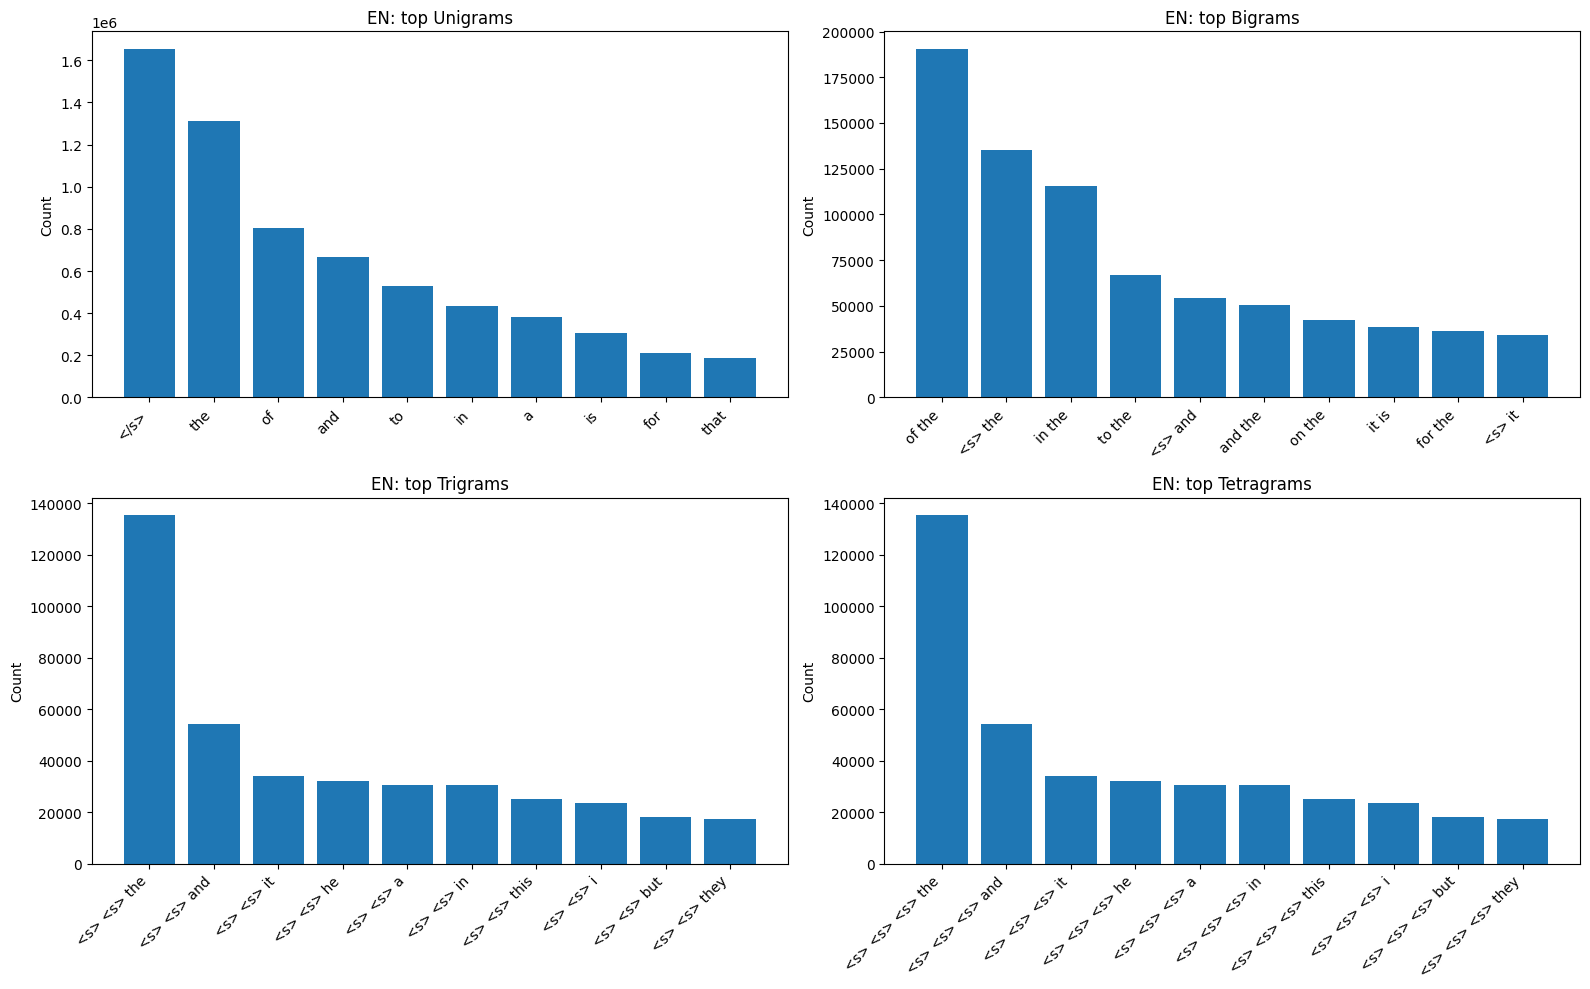

/tmp/ipykernel_58/3268428888.py:108: UserWarning: Glyph 108 (l) missing from font(s) Noto Serif Devanagari.
  plt.tight_layout()
/tmp/ipykernel_58/3268428888.py:108: UserWarning: Glyph 112 (p) missing from font(s) Noto Serif Devanagari.
  plt.tight_layout()
/tmp/ipykernel_58/3268428888.py:108: UserWarning: Glyph 115 (s) missing from font(s) Noto Serif Devanagari.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 108 (l) missing from font(s) Noto Serif Devanagari.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 112 (p) missing from font(s) Noto Serif Devanagari.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 115 (s) missing from font(s) Noto Serif Devanagari.
  fig.canvas.print_figure(bytes_io, **kw)


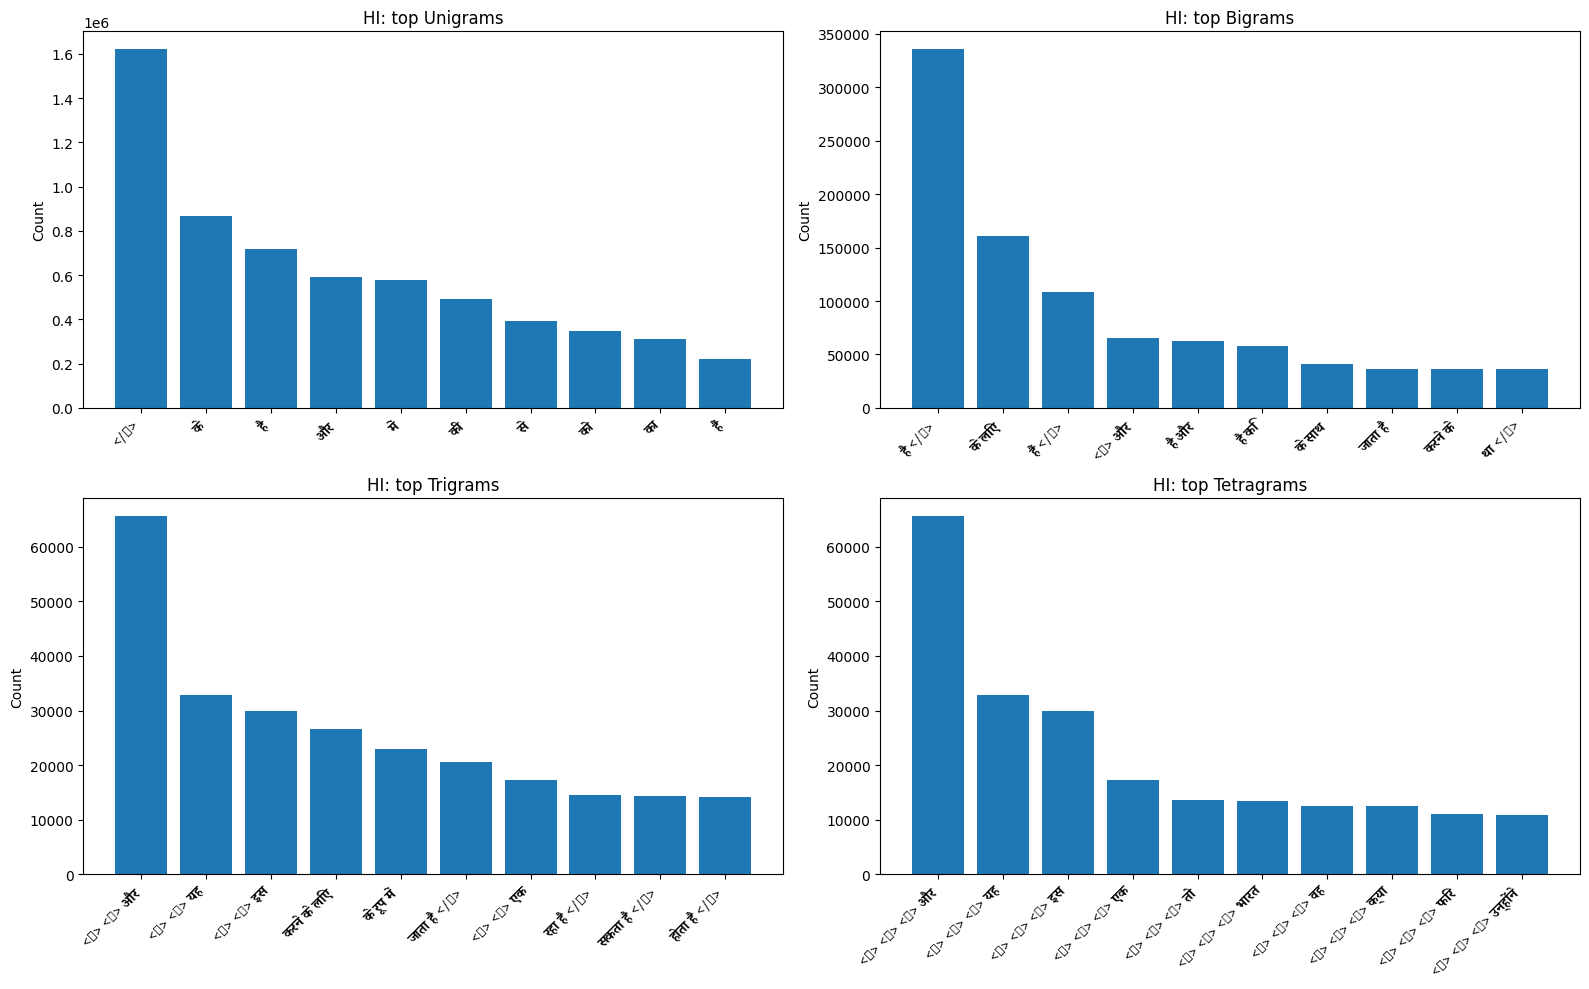

In [21]:
print_most_frequent(ngram_models)
plot_most_frequent(ngram_models)

## Step-2: Sentence Probability: **[100 + 100 marks]**

1. Pick up 1000 random sentences from the corpus. Calculate the sentence probability separately using unigram, bigram, trigram and tetragram models. What do you observe? Is the probability same for unigram, bigram, trigram and tetragram models?
2. Given a sentence such as **"Lewis Hamilton is a"**, can you predict the next word that can come after "is a"? Try to predict separately with using unigram, bigram, trigram amd tetragram models. Which model gives the best prediction?

Given the reliance of n-gram models on the presence of sequential tokens in the training data, there exists a situation where the queried n-gram is not present in the training data. For example, there may be a trigram sequence that is not there in the trigram model or in the training data then how can one calculate the sentence probability? Now we look at 3 popular methods to handle this situation.

1. **Backoff Model:** When predicting the sentence probability of a target sentence using an n-gram model we can switch to an (n-1)-gram model if the queried sequence is not there in the n-gram model. For example, if `[Monza, is, in]` is not a part of the tri-gram model we can predict the probability of the above phrase by taking the product of the bi-gram probabilities of `[Monza, is]` and `[is, in]`. In a backoff-model one can keep repeating this process till we reach a uni-gram model. However, backoff is only applied to the n-gram sequence that is not found in the n-gram model, while the probability of the rest of the sequence is calculated as is. Please refer to [Lecture-3 Language models](https://web.cs.hacettepe.edu.tr/~ilyas/Courses/CMP711/lec03-LanguageModels.pdf) for a deeper understanding of backoff models.
2. **Smoothing:** When calculating the n-gram sequence probabilty of new/unknown (not part of training data or model) sequence, we can replace $0$ with a value $\epsilon << 1$, to prevent the probability from collapsing to $0$. This method is called smoothing.
3. **Linear Interpolation:** N-gram probability of the next word can also be computed as a linear sum of tetragram, trigram, bigram and unigram probabilities.
$$
P(w_n \mid w_{n-1}, w_{n-2}, w_{n-3}) = \lambda_1 P(w_n \mid w_{n-1}, w_{n-2}, w_{n-3}) + λ_2P(w_n \mid w_{n-1}, w_{n-2}) + λ_3P(w_n \mid w_{n-1}) + λ_4P(w_n)
$$
Under the constraint that $\lambda_1 + \lambda_2 + \lambda_3 + \lambda_4 = 1$. The $\lambda$ values can be estimated by dividing the data into 2 parts calling them `train` and `val` splits.

In [27]:
import random
import math
import re
from collections import Counter, defaultdict
from tqdm import tqdm  # Imported for progress bars

# =========================================================
# 1. Corpus Tokenization & Fast Boundary Padding
# =========================================================
raw_english = [row['en'] for row in dataset['translation'] if row.get('en')]

print("Tokenizing corpus...")
tokenized_corpus = []
for sentence in tqdm(raw_english, desc="Tokenizing Sentences"):
    tokens = re.findall(r'\b[a-zA-Z]+\b', str(sentence).lower())
    if len(tokens) > 0:
        tokenized_corpus.append(tokens)

# =========================================================
# 2. Single-Pass Fast Count & Transition Map Precomputation
# =========================================================
ngram_counts = {1: Counter(), 2: Counter(), 3: Counter(), 4: Counter()}
history_counts = {2: Counter(), 3: Counter(), 4: Counter()}
context_transitions = {2: defaultdict(Counter), 3: defaultdict(Counter), 4: defaultdict(Counter)}

print("Precomputing n-gram counts and transition maps...")
for sentence in tqdm(tokenized_corpus, desc="Building N-Grams"):
    # 1-gram with end-of-sentence token
    for word in sentence:
        ngram_counts[1][word] += 1
    ngram_counts[1]['</s>'] += 1

    # Single padded array for higher-order n-grams
    padded = ['<s>', '<s>', '<s>'] + sentence + ['</s>']
    pad_len = len(padded)

    # Bigrams (n=2)
    for i in range(2, pad_len):
        w1, w2 = padded[i - 1], padded[i]
        ngram_counts[2][(w1, w2)] += 1
        history_counts[2][(w1,)] += 1
        if w2 != '</s>':
            context_transitions[2][(w1,)][w2] += 1

    # Trigrams (n=3)
    for i in range(2, pad_len):
        w1, w2, w3 = padded[i - 2], padded[i - 1], padded[i]
        ngram_counts[3][(w1, w2, w3)] += 1
        history_counts[3][(w1, w2)] += 1
        if w3 != '</s>':
            context_transitions[3][(w1, w2)][w3] += 1

    # Tetragrams (n=4)
    for i in range(3, pad_len):
        w1, w2, w3, w4 = padded[i - 3], padded[i - 2], padded[i - 1], padded[i]
        ngram_counts[4][(w1, w2, w3, w4)] += 1
        history_counts[4][(w1, w2, w3)] += 1
        if w4 != '</s>':
            context_transitions[4][(w1, w2, w3)][w4] += 1

TOTAL_UNIGRAMS = sum(ngram_counts[1].values())
VOCAB_SIZE = len(ngram_counts[1])
GLOBAL_UNIGRAM_TOP = next(
    w for w, _ in ngram_counts[1].most_common(10) if w not in ('<s>', '</s>')
)

# =========================================================
# 3. Probability & Sentence Scoring Functions
# =========================================================
def get_smoothed_prob(ngram, n, epsilon=1e-5):
    if n == 1:
        word = ngram if isinstance(ngram, str) else ngram[0]
        return (ngram_counts[1].get(word, 0) + epsilon) / (TOTAL_UNIGRAMS + epsilon * VOCAB_SIZE)

    history = ngram[:-1]
    ngram_c = ngram_counts[n].get(ngram, 0)
    hist_c = history_counts[n].get(history, 0)
    return (ngram_c + epsilon) / (hist_c + epsilon * VOCAB_SIZE)

def compute_sentence_log_prob(tokens, n, epsilon=1e-5):
    log_p = 0.0
    if n == 1:
        for w in tokens:
            log_p += math.log(get_smoothed_prob(w, 1, epsilon))
        log_p += math.log(get_smoothed_prob('</s>', 1, epsilon))
        return log_p

    padded = ['<s>'] * (n - 1) + tokens + ['</s>']
    for i in range(len(padded) - n + 1):
        ng = tuple(padded[i:i + n])
        log_p += math.log(get_smoothed_prob(ng, n, epsilon))
    return log_p

# =========================================================
# 4. Instantaneous O(1) Next-Word Prediction
# =========================================================
def predict_next_word(context_str, n):
    if n == 1:
        return GLOBAL_UNIGRAM_TOP

    context_tokens = re.findall(r'\b[a-zA-Z]+\b', context_str.lower())
    history_len = n - 1
    if len(context_tokens) < history_len:
        return "<Not enough context>"

    target_history = tuple(context_tokens[-history_len:])
    transitions = context_transitions[n].get(target_history)
    
    if transitions:
        return transitions.most_common(1)[0][0]
    return "<Unknown (Zero Count in Training Data)>"

# =========================================================
# 5. Execution of Task 1 & Task 2
# =========================================================
print("\n==========================================")
print("TASK 1: Sentence Probability Estimation")
print("==========================================")
random.seed(42)
sample_1000 = random.sample(tokenized_corpus, min(1000, len(tokenized_corpus)))

avg_log_probs = {}
for n in range(1, 5):
    total_log_p = 0
    # Added tqdm progress bar for scoring the 1000 sentences
    for s in tqdm(sample_1000, desc=f"Evaluating {n}-gram model"):
        total_log_p += compute_sentence_log_prob(s, n)
        
    avg_log_probs[n] = total_log_p / len(sample_1000)
    print(f"-> Average Log Probability ({n}-gram model): {avg_log_probs[n]:.4f}\n")

print("==========================================")
print("TASK 2: Next-Word Prediction")
print("==========================================")
prompt = "Lewis Hamilton is a"
print(f"Context Prompt: '{prompt}'\n")

for n, name in [(1, "Unigram"), (2, "Bigram"), (3, "Trigram"), (4, "Tetragram")]:
    pred = predict_next_word(prompt, n)
    history = "None (Global Mode)" if n == 1 else " ".join(re.findall(r'[a-zA-Z]+', prompt.lower())[-(n-1):])
    print(f"• {name} (n={n}) [History: '{history}']: '{pred}'")

Tokenizing corpus...


Tokenizing Sentences: 100%|██████████| 1658362/1658362 [00:12<00:00, 133494.59it/s]


Precomputing n-gram counts and transition maps...


Building N-Grams: 100%|██████████| 1651806/1651806 [03:41<00:00, 7451.03it/s] 



TASK 1: Sentence Probability Estimation


Evaluating 1-gram model: 100%|██████████| 1000/1000 [00:00<00:00, 139982.78it/s]


... (3 outputs left out)

Evaluating 3-gram model: 100%|██████████| 1000/1000 [00:00<00:00, 43421.99it/s]


-> Average Log Probability (3-gram model): -45.5439



Evaluating 4-gram model: 100%|██████████| 1000/1000 [00:00<00:00, 44966.59it/s]

-> Average Log Probability (4-gram model): -29.2375

TASK 2: Next-Word Prediction
Context Prompt: 'Lewis Hamilton is a'

• Unigram (n=1) [History: 'None (Global Mode)']: 'the'
• Bigram (n=2) [History: 'a']: 'new'
• Trigram (n=3) [History: 'is a']: 'sign'
• Tetragram (n=4) [History: 'hamilton is a']: '<Unknown (Zero Count in Training Data)>'


In [31]:
import math
import random
import pandas as pd
import numpy as np


def sentence_log_probability(tokens, counts, histories, n):
    """Calculate the MLE sentence probability and return its natural logarithm."""
    log_probability = 0.0
    for ngram in generate_ngrams(tokens, n):
        probability = ngram_probability(ngram, counts, histories)
        if probability == 0:
            return float("-inf")
        log_probability += math.log(probability)
    return log_probability


def scientific_probability(log_probability):
    """Write very small probabilities without floating-point underflow."""
    if not math.isfinite(log_probability):
        return "0"
    log10_probability = log_probability / math.log(10)
    exponent = math.floor(log10_probability)
    mantissa = 10 ** (log10_probability - exponent)
    return f"{mantissa:.6f}e{exponent:+d}"


def calculate_1000_sentence_probabilities(
    dataset, models, histories, sample_size=1000, seed=42
):
    """Pick 1,000 parallel rows and calculate all four sentence probabilities."""
    rows_used_to_train = (
        len(dataset)
        if NGRAM_MAX_ROWS is None
        else min(NGRAM_MAX_ROWS, len(dataset))
    )
    if rows_used_to_train < sample_size:
        raise ValueError("At least 1,000 training sentences are required.")

    chosen_rows = random.Random(seed).sample(range(rows_used_to_train), sample_size)
    tokenizers = {"en": tokenize_english, "hi": tokenize_hindi}
    readable_tables = {}
    log_tables = {}

    for lang in ("en", "hi"):
        readable_rows = []
        log_rows = []

        for sample_number, row_index in enumerate(chosen_rows, start=1):
            sentence = dataset[row_index]["translation"].get(lang, "")
            tokens = tokenizers[lang](sentence)
            log_values = {
                n: sentence_log_probability(
                    tokens, models[lang], histories[lang], n
                )
                for n in range(1, 5)
            }

            readable_rows.append(
                {
                    "sample": sample_number,
                    "corpus row": row_index,
                    "sentence": sentence,
                    "unigram P(sentence)": scientific_probability(log_values[1]),
                    "bigram P(sentence)": scientific_probability(log_values[2]),
                    "trigram P(sentence)": scientific_probability(log_values[3]),
                    "tetragram P(sentence)": scientific_probability(log_values[4]),
                }
            )
            log_rows.append(
                {
                    "unigram": log_values[1],
                    "bigram": log_values[2],
                    "trigram": log_values[3],
                    "tetragram": log_values[4],
                }
            )

        readable_tables[lang] = pd.DataFrame(readable_rows)
        log_tables[lang] = pd.DataFrame(log_rows)

    return readable_tables, log_tables


def probability_observation_table(log_tables):
    """Summarize whether the four probabilities agree on the sampled sentences."""
    rows = []
    for lang, table in log_tables.items():
        values = table[["unigram", "bigram", "trigram", "tetragram"]].to_numpy()
        largest_orders = np.argmax(values, axis=1)
        equal_count = np.sum(np.ptp(values, axis=1) < 1e-12)

        for column_number, model in enumerate(table.columns):
            rows.append(
                {
                    "language": lang,
                    "model": model,
                    "mean log P(sentence)": table[model].mean(),
                    "largest probability for": int(np.sum(largest_orders == column_number)),
                    "all four probabilities equal": int(equal_count),
                }
            )
    return pd.DataFrame(rows)


sentence_probability_tables, sentence_log_tables = (
    calculate_1000_sentence_probabilities(
        dataset, ngram_models, history_counts, sample_size=1000, seed=42
    )
)

for lang, table in sentence_probability_tables.items():
    print(f"{lang.upper()}: probabilities calculated for {len(table)} random sentences")
    display(table)

print("Direct comparison of the four models on the 1,000 sentences:")
display(probability_observation_table(sentence_log_tables))


def top_continuations(context_tokens, counts, histories, n, top_k=5):
    """Return the most probable observed continuations for one model order."""
    if n == 1:
        denominator = sum(counts[1].values())
        candidates = [
            (ngram[0], count, count / denominator)
            for ngram, count in counts[1].most_common()
            if ngram[0] not in {"<s>", "</s>"}
        ]
        return candidates[:top_k], "no context"

    history = tuple(context_tokens[-(n - 1):])
    denominator = histories[n].get(history, 0)
    if denominator == 0:
        return [], " ".join(history)

    candidates = [
        (ngram[-1], count, count / denominator)
        for ngram, count in counts[n].items()
        if ngram[:-1] == history and ngram[-1] != "</s>"
    ]
    candidates.sort(key=lambda item: (-item[1], item[0]))
    return candidates[:top_k], " ".join(history)


query_tokens = tokenize_english("Lewis Hamilton is a")
prediction_rows = []
supported_predictions = []

for order, model_name in enumerate(
    ("Unigram", "Bigram", "Trigram", "Tetragram"), start=1
):
    candidates, history = top_continuations(
        query_tokens, ngram_models["en"], history_counts["en"], order
    )

    if candidates:
        word, count, probability = candidates[0]
        supported_predictions.append((order, model_name, word))
        prediction_rows.append(
            {
                "model": model_name,
                "history used": history,
                "predicted next word": word,
                "count": count,
                "conditional probability": probability,
            }
        )
    else:
        prediction_rows.append(
            {
                "model": model_name,
                "history used": history,
                "predicted next word": "No observed continuation",
                "count": 0,
                "conditional probability": 0.0,
            }
        )

prediction_table = pd.DataFrame(prediction_rows)
display(prediction_table)

best_order, best_model, best_word = max(supported_predictions, key=lambda row: row[0])
print(
    f"Best supported model for this query: {best_model} -> '{best_word}'. "
    f"It is the highest-order model whose history occurs in the corpus."
)


EN: probabilities calculated for 1000 random sentences


,sample,corpus row,sentence,unigram P(sentence),bigram P(sentence),trigram P(sentence),tetragram P(sentence)
0,1,1340975,When the banyan 's leaves are still pink and t...,1.015715e-90,3.712511e-71,2.941941e-29,5.036184e-9
1,2,233478,First page:,8.480580e-9,1.029786e-6,1.012705e-5,1.087816e-5
2,3,52451,Whether to show popup notifications when away ...,1.734956e-32,4.987806e-20,6.525486e-8,3.548826e-6
3,4,1555144,The Vrindavan Chandrodaya Mandir will strive t...,5.066806e-125,1.094448e-80,1.841473e-42,4.892898e-18
4,5,576778,are 100 percent.,3.093553e-8,1.161485e-8,1.342982e-7,6.043421e-7
...,...,...,...,...,...,...,...
995,996,1548966,The President congratulated ISKCON for their e...,9.239169e-67,1.727352e-44,1.490130e-19,2.041005e-10
996,997,1015438,Account depicting deficiency.,3.843608e-15,1.511893e-10,2.014474e-7,6.043421e-7
997,998,579861,Switch input source,2.363757e-14,9.521501e-10,7.770112e-7,6.043421e-7
998,999,1519564,"I am informed that the ‘Cottayam College’, whi...",1.481092e-72,6.209988e-49,5.738731e-28,1.824950e-12


HI: probabilities calculated for 1000 random sentences


,sample,corpus row,sentence,unigram P(sentence),bigram P(sentence),trigram P(sentence),tetragram P(sentence)
0,1,1340975,"जब बरगद के नए पत्ते गुलाबी और नर्म होते हैं, त...",3.153663e-90,1.763969e-60,3.768316e-21,1.623950e-8
1,2,233478,à¤ªà¥à¤°à¤µà¤¿à¤·à¥à¤à¤¿ à¤à¥à¤¡à¤¼à¥à¤,6.607142e-2,0,0,0
2,3,52451,क्या पॉप अप अधिसूचना दिखानी है जब दूर या व्यस्...,8.199403e-40,1.234853e-21,1.064984e-9,2.028206e-6
3,4,1555144,वृंदावन चंद्रोदय मंदिर सरल और तार्किक विधि से ...,9.534714e-123,2.810383e-77,1.484140e-37,1.678919e-19
4,5,576778,पूरी सौ प्रतिशत।,5.294603e-13,8.028088e-12,2.683048e-8,6.171011e-7
...,...,...,...,...,...,...,...
995,996,1548966,राष्ट्रपति ने विश्व भर में भगवान कृष्ण के कालज...,7.316853e-76,7.549720e-49,5.928960e-26,1.148801e-14
996,997,1015438,न्यूनता दर्शाता लेखा।,3.634692e-16,2.425509e-11,6.171011e-7,6.171011e-7
997,998,579861,इनपुट स्रोत स्विच करें,1.067917e-17,1.465423e-10,4.029473e-7,6.171011e-7
998,999,1519564,मुझे यह बताया गया है कि सेमिनारी में सह-स्थापि...,3.544028e-66,3.117012e-43,3.830952e-19,4.401742e-10


Direct comparison of the four models on the 1,000 sentences:


,language,model,mean log P(sentence),largest probability for,all four probabilities equal
0,en,unigram,-93.345708,9,0
1,en,bigram,-inf,26,0
2,en,trigram,-inf,218,0
3,en,tetragram,-inf,747,0
4,hi,unigram,-106.001422,29,0
5,hi,bigram,-inf,47,0
6,hi,trigram,-inf,206,0
7,hi,tetragram,-inf,718,0


,model,history used,predicted next word,count,conditional probability
0,Unigram,no context,the,1314220,0.057799
1,Bigram,a,new,8341,0.021881
2,Trigram,is a,sign,502,0.018132
3,Tetragram,hamilton is a,No observed continuation,0,0.000000


Best supported model for this query: Trigram -> 'sign'. It is the highest-order model whose history occurs in the corpus.


## Step-3: Analytical Questions [20 x 2 = 40 Marks]

1. **What other smoothing methods do you know? Can they be applied here?**

Several alternatives are available:

- **Add-(k) (Laplace when (k=1)) smoothing** adds a small pseudo-count to every possible continuation. The code above uses the same idea with a very small (epsilon). It prevents a single unseen n-gram from making the whole sentence probability zero, although large (k) values usually move too much probability mass to unseen events.
- **Good-Turing smoothing** estimates the mass of unseen n-grams from the number of n-grams seen once, twice, and so on. It can be applied here, but it needs careful handling of count-of-counts values.
- **Witten-Bell smoothing** reserves probability mass according to the number of distinct continuations observed after a history. It is suitable for these models and is simpler than Good-Turing in many cases.
- **Katz backoff** discounts seen n-grams and backs off to a lower-order model for an unseen event. The backoff prediction function above demonstrates the basic idea, although a full Katz model would also estimate discount factors.
- **Interpolated Kneser-Ney** is generally the strongest classical choice. It combines discounted probabilities from all orders and uses continuation counts, which helps common words that occur in many different contexts. It can be applied to the stored counts, with interpolation weights or discounts estimated on validation data.


2. **Can you do a cross-language comparison of unigram, bigram, trigram and tetragram models without training them again?**

Yes, provided the English and Hindi count tables have already been built and retained, as they are in `ngram_models`. No re-training is needed: evaluate each saved model on the corresponding side of the same held-out parallel sentences.

Raw sentence probabilities should not be compared directly because the translations can have different token counts, and the two vocabularies have different sizes. A fairer comparison is mean log-probability per predicted token or perplexity, using the same tokenization and smoothing rule for both languages. The `probability_summary` table reports exactly these normalized quantities. This comparison says which model predicts its own language more easily under the chosen representation; it does not mean that an English model can be used directly to score Hindi, since their tokens and count tables are different.
